# Reproducing MLM and residue-classification loss curves

This tutorial rebuilds the figures in `reports/training_validation_loss_report.md` from recorded run artifacts. It covers the small ESM++ masked-language-model (MLM) run and the five-epoch 3Di per-residue classifier initialized from that MLM checkpoint.

**Audience:** project contributors auditing or refreshing the figures.  
**Prerequisites:** Python with `matplotlib` and `pandas`; start in the repository root.  
**Learning goals:** locate artifacts, extract epoch and batch-running-average losses, and render the three-panel figure.


## Outline

1. Set the recorded artifact paths.
2. Extract MLM epoch summaries from its text log.
3. Extract classifier epoch summaries and the batch running average from its TensorBoard event file.
4. Plot and save training/validation curves plus the running-average trajectory.
5. Inspect the dataset and run manifest.


In [1]:
from __future__ import annotations

from pathlib import Path
import re
import struct

import matplotlib.pyplot as plt
import pandas as pd
REPO_ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (path / ".git").exists())
MLM_LOG = REPO_ROOT / 'esmc_viral_ft' / 'train.log'
CLASSIFIER_EVENT = REPO_ROOT / 'tensorboard_logs' / 'esm3di_from_mlm' / 'run_20260326_212108' / 'events.out.tfevents.1774556468.dmoi-WS-C621E-SAGE-Series.3837185.0'
REPORT_FIGURE = REPO_ROOT / 'reports' / 'assets' / 'training_validation_loss_curves.png'

for artifact in (MLM_LOG, CLASSIFIER_EVENT):
    if not artifact.is_file():
        raise FileNotFoundError(f'Missing required artifact: {artifact}')

print(f'Repository: {REPO_ROOT}')
print(f'MLM log: {MLM_LOG.relative_to(REPO_ROOT)}')
print(f'Classifier event: {CLASSIFIER_EVENT.relative_to(REPO_ROOT)}')

Repository: /home/dmoi/projects/ESM3di
MLM log: esmc_viral_ft/train.log
Classifier event: tensorboard_logs/esm3di_from_mlm/run_20260326_212108/events.out.tfevents.1774556468.dmoi-WS-C621E-SAGE-Series.3837185.0


## Step 1 — Read the MLM log

The small ESM++ MLM run (`esmc_viral_ft`) writes one training and validation loss summary per epoch to `train.log`. This selects only those summaries, rather than frequent step-level losses.

In [2]:
epoch_pattern = re.compile(r'Epoch (?P<epoch>\d+): train_loss=(?P<train>[0-9.]+) val_loss=(?P<val>[0-9.]+)')
mlm_losses = pd.DataFrame([
    {'epoch': int(m['epoch']), 'train_loss': float(m['train']), 'val_loss': float(m['val'])}
    for m in epoch_pattern.finditer(MLM_LOG.read_text())
])
assert len(mlm_losses) == 3, 'Expected the recorded three-epoch MLM run.'
mlm_losses

,epoch,train_loss,val_loss
0,1,2.362477,2.359371
1,2,2.331953,2.336219
2,3,2.306546,2.328680


## Step 2 — Read classifier losses from TensorBoard

The classifier event stream includes high-frequency batch summaries. The helper extracts the recorded scalar values without re-computing loss. In addition to the two epoch tags, it reads `Loss/train_running_avg`, the run's logged moving average of training loss over batches. The event records are read in TensorBoard's TFRecord format so the plot retains each scalar's global step.


In [3]:
def decode_varint(payload: bytes, offset: int) -> tuple[int, int]:
    value, shift = 0, 0
    while True:
        byte = payload[offset]
        offset += 1
        value |= (byte & 0x7F) << shift
        if not byte & 0x80:
            return value, offset
        shift += 7


def tensorboard_scalar_series(event_path: Path, tag: str) -> pd.DataFrame:
    """Read a scalar tag and its TensorBoard global steps from TFRecord events."""
    payload = event_path.read_bytes()
    marker = bytes([0x0A, len(tag)]) + tag.encode() + bytes([0x15])
    rows, offset = [], 0
    while offset + 16 <= len(payload):
        record_length = struct.unpack_from('<Q', payload, offset)[0]
        event_start = offset + 12  # 8-byte length plus 4-byte masked CRC
        event_end = event_start + record_length
        event = payload[event_start:event_end]
        offset = event_end + 4  # trailing masked CRC
        scalar_offset = event.find(marker)
        if scalar_offset < 0:
            continue
        # Event protobuf: wall_time (fixed64), then global_step (varint).
        step = 0
        if len(event) > 9 and event[9] == 0x10:
            step, _ = decode_varint(event, 10)
        value_start = scalar_offset + len(marker)
        rows.append({'step': step, 'loss': struct.unpack('<f', event[value_start:value_start + 4])[0]})
    return pd.DataFrame(rows)


train_epoch = tensorboard_scalar_series(CLASSIFIER_EVENT, 'Loss/train_epoch')
val_epoch = tensorboard_scalar_series(CLASSIFIER_EVENT, 'Loss/val_epoch')
running_average = tensorboard_scalar_series(CLASSIFIER_EVENT, 'Loss/train_running_avg')

classifier_losses = pd.DataFrame({
    'epoch': range(1, 6),
    'train_loss': train_epoch['loss'],
    'val_loss': val_epoch['loss'],
})
assert len(classifier_losses) == 5, 'Expected the recorded five-epoch classifier run.'
assert len(running_average) == 4_939, 'Expected every logged batch running-average value.'
print(f'Running-average points: {len(running_average):,}; steps {running_average.step.min():,}–{running_average.step.max():,}')
classifier_losses


Running-average points: 4,939; steps 10–49,390


,epoch,train_loss,val_loss
0,1,1.574463,1.372658
1,2,1.348761,1.327600
2,3,1.298178,1.303134
3,4,1.266426,1.295301
4,5,1.249222,1.296983


## Step 3 — Compile the figure

The first two panels show one training and validation loss per epoch. The third panel shows the classifier's recorded `Loss/train_running_avg` trajectory across batch updates; it is a smoothed training signal, not a validation curve. Loss scales differ across objectives, so each panel has its own y axis.


Wrote reports/assets/training_validation_loss_curves.png


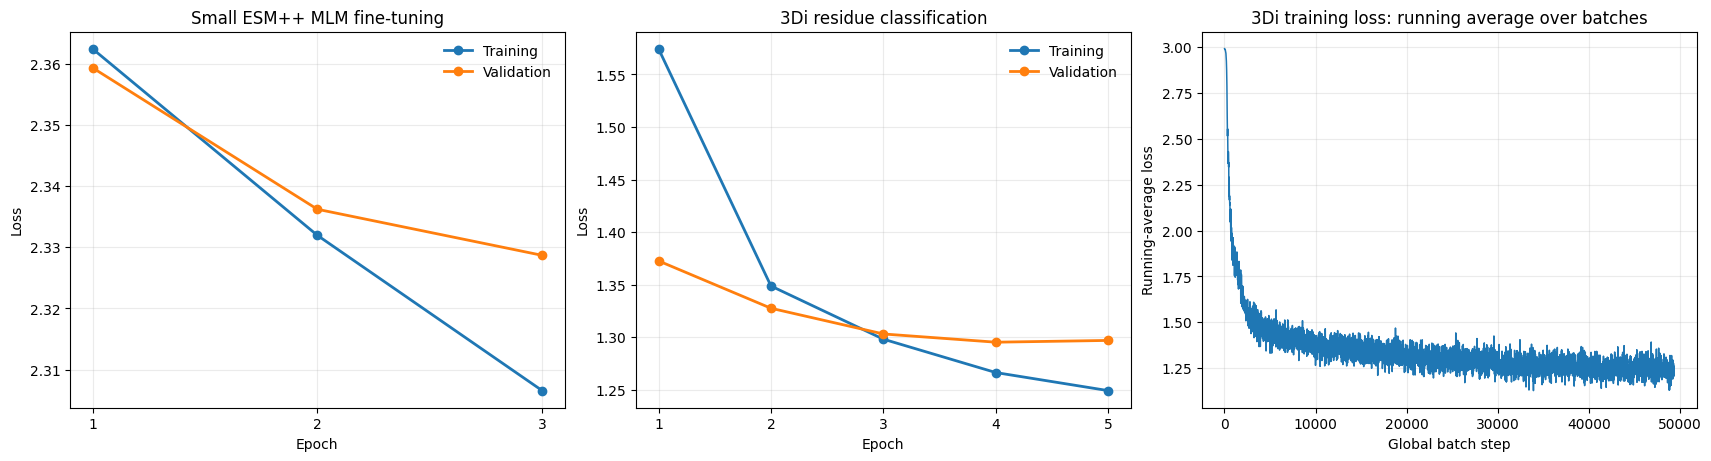

In [4]:
def plot_epoch_losses(ax, losses: pd.DataFrame, title: str) -> None:
    ax.plot(losses['epoch'], losses['train_loss'], marker='o', linewidth=2, label='Training')
    ax.plot(losses['epoch'], losses['val_loss'], marker='o', linewidth=2, label='Validation')
    ax.set(title=title, xlabel='Epoch', ylabel='Loss')
    ax.set_xticks(losses['epoch'])
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)


fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
plot_epoch_losses(axes[0], mlm_losses, 'Small ESM++ MLM fine-tuning')
plot_epoch_losses(axes[1], classifier_losses, '3Di residue classification')
axes[2].plot(running_average['step'], running_average['loss'], color='tab:blue', linewidth=1.1)
axes[2].set(
    title='3Di training loss: running average over batches',
    xlabel='Global batch step',
    ylabel='Running-average loss',
)
axes[2].grid(alpha=0.25)
REPORT_FIGURE.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(REPORT_FIGURE, dpi=180, bbox_inches='tight')
print(f'Wrote {REPORT_FIGURE.relative_to(REPO_ROOT)}')
plt.show()


## Dataset and run manifest

Both stages use BFVD split files under `/mnt/data1/bfvd/training_set_nomasking/splits/`: 316,117 training, 1,756 validation, and 33,369 test sequences. MLM consumes amino-acid FASTA sequences. The classifier consumes paired amino-acid and unmasked 3Di FASTA sequences, with pLDDT-bin FASTA files for weighting and stratified metrics.

The MLM checkpoint is `esmc_viral_ft/epoch_3/` (small ESM++; 30 layers, 960 hidden size, 15 attention heads). The selected classifier configuration is `configs/config_mlm_resume_3di.json`: five epochs, batch size 4, gradient accumulation 8, AdamW at `1e-4`, cosine schedule with 10% warmup, a two-layer CNN head (kernel 3), and LoRA (`r=16`, alpha 32, dropout 0.01).

In [5]:
run_manifest = pd.DataFrame([
    {'stage': 'MLM fine-tuning', 'artifact': 'esmc_viral_ft/train.log; esmc_viral_ft/epoch_3/', 'objective': 'masked amino-acid token prediction', 'epochs': 3, 'train / val / test sequences': '316,117 / 1,756 / 33,369'},
    {'stage': '3Di residue classification', 'artifact': 'tensorboard_logs/esm3di_from_mlm/run_20260326_212108/', 'objective': 'per-residue 3Di token classification from amino acids', 'epochs': 5, 'train / val / test sequences': '316,117 / 1,756 / 33,369'},
])
run_manifest

,stage,artifact,objective,epochs,train / val / test sequences
0,MLM fine-tuning,esmc_viral_ft/train.log; esmc_viral_ft/epoch_3/,masked amino-acid token prediction,3,"316,117 / 1,756 / 33,369"
1,3Di residue classification,tensorboard_logs/esm3di_from_mlm/run_20260326_...,per-residue 3Di token classification from amin...,5,"316,117 / 1,756 / 33,369"


## Interpretation, exercise, and pitfalls

MLM validation loss falls from 2.359 to 2.329 over three epochs. Classifier validation loss falls from 1.373 to its best recorded value, 1.295, at epoch 4, then is essentially flat at epoch 5 (1.297). Its batch-level running average shows the corresponding within-run convergence across the logged training steps.

**Exercise:** point `CLASSIFIER_EVENT` to another completed run and confirm that both epoch tags contain five values and that `Loss/train_running_avg` is populated before comparing curves.

**Common pitfall:** do not treat the running-average curve as validation loss or compare loss magnitudes across panels as if they had the same objective. Compare convergence and the train/validation gap within each task.
